# CellVOCAL analysis of human liver injury

This tutorial presents the human-liver analysis as a Methods workflow. A prepared spatial H5AD section supplies spliced and unspliced expression, and a common LR table keeps the communication prior identical across donors and conditions. The example uses one APAP-injured section; select another prepared section by changing `SAMPLE`.

> Start Jupyter from the repository root. Training is commented by default and downstream cells load the fitted `out.h5ad`.

**Required files.** Place prepared inputs under `paper/data/human_liver/raw/`
and fitted H5AD files and checkpoints under `paper/data/human_liver/cellvocal/`.
The shared LR table at `paper/data/human_liver/lr_hits/lr_hits.csv` is not
bundled. To inspect saved fits without this table, comment out the
`lr_table = ...` and `lr_pairs = ...` lines in the configuration cell and keep
training commented out. The analysis cells use the fitted H5AD files and
checkpoints directly.

To train with the same common prior as the saved fits, provide that LR table.
Alternatively, configure the local CellChatDB through the public pipeline as
described in [PIPELINE.md](../../PIPELINE.md); the selected LR prior can differ
from the one used for the saved fits. These examples use the `pipeline`,
`model`, and `utils` APIs.

## Model specification

The spatial graph uses 16 neighbors and retains four candidate signaling events per receiver. Cell-type embeddings are disabled so the learned dynamics are driven by RNA state, spatial proximity, and the shared ligand-receptor prior rather than supplied annotations.

In [1]:
from base64 import b64encode
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "model").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import anndata as ad
import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, display
from IPython.utils.capture import capture_output

from model.train.config import CellVOCALConfig
from pipeline.analysis import CellVOCALAnalysis
from pipeline.cellvocal import run_cellvocal


In [2]:
DATA_ROOT = ROOT / "paper" / "data" / "human_liver"
SAMPLE = "APAP_liver_spatial_01_A"

lr_table = pd.read_csv(DATA_ROOT / "lr_hits" / "lr_hits.csv").fillna("")
lr_pairs = [{**row, "ligand_genes": str(row["ligand_genes"]).split(";"), "receptor_genes": str(row["receptor_genes"]).split(";")} for row in lr_table.to_dict("records")]

cfg = CellVOCALConfig()
cfg.translator.mode = "train"
cfg.translator.cellchatdb_dir = ROOT / "resource" / "cellchatdb"
cfg.translator.cellchat_species = "human"
cfg.model.use_cell_annotation = False
cfg.graph.n_spatial_neighbors = 16
cfg.graph.ccc_event_budget_per_receiver = 4
cfg.train.velocity_target_unspliced_layer = "unspliced"
cfg.train.velocity_target_spliced_layer = "spliced"
cfg.train.lr = 5e-6
cfg.train.w_time = 0.8
cfg.train.device = "cuda:0" if torch.cuda.is_available() else "cpu"
cfg.train.checkpoint_dir = DATA_ROOT / "cellvocal" / SAMPLE / "checkpoints"
cfg.eval.output_dir = DATA_ROOT / "cellvocal" / SAMPLE / "results"

## Train CellVOCAL

The prepared input is used without an additional generation or preprocessing stage. Uncomment the two lines below to refit this section. `run_cellvocal` writes the canonical result to `cfg.eval.output_dir / 'out.h5ad'`.

The commented call below also needs the shared `lr_pairs` table described in the availability note above.

In [3]:
# adata = ad.read_h5ad(DATA_ROOT / "raw" / f"{SAMPLE}.h5ad")
# result = run_cellvocal(adata, config=cfg, lr_pairs=lr_pairs)

## Read the fitted APAP section

The fitted section retains cell-type proportion estimates for downstream analysis, although the model does not use cell-type embeddings. The overview reports sample identity, spot/gene counts, inferred-time range, and event coverage; the spatial maps remain side by side below.


,value
condition,APAP
donor,APAP_01
spots,"2,604"
genes,"1,360"
inferred-time range,0.094–0.859
candidate CCC events,"15,207"
receiver coverage,78.7%


2 velocity plots in one row
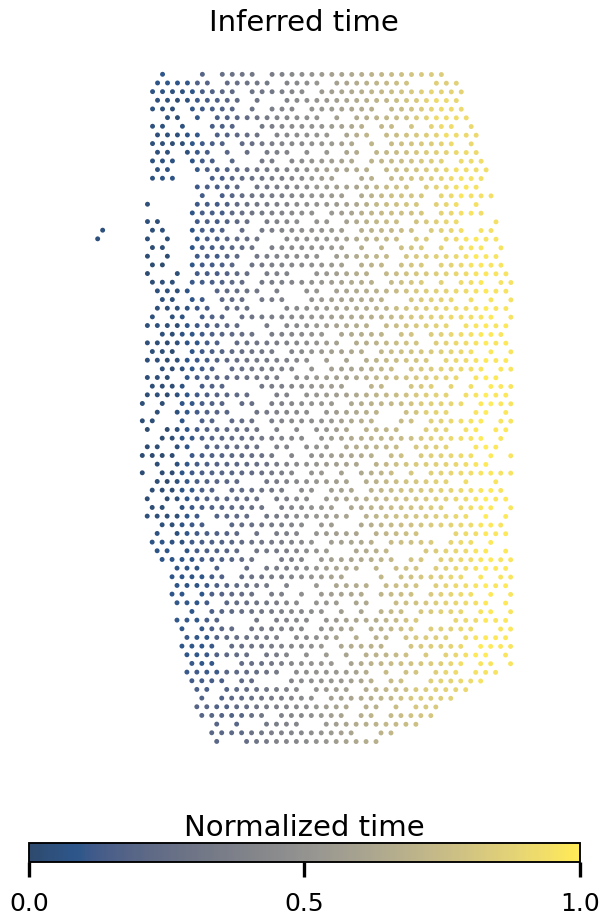
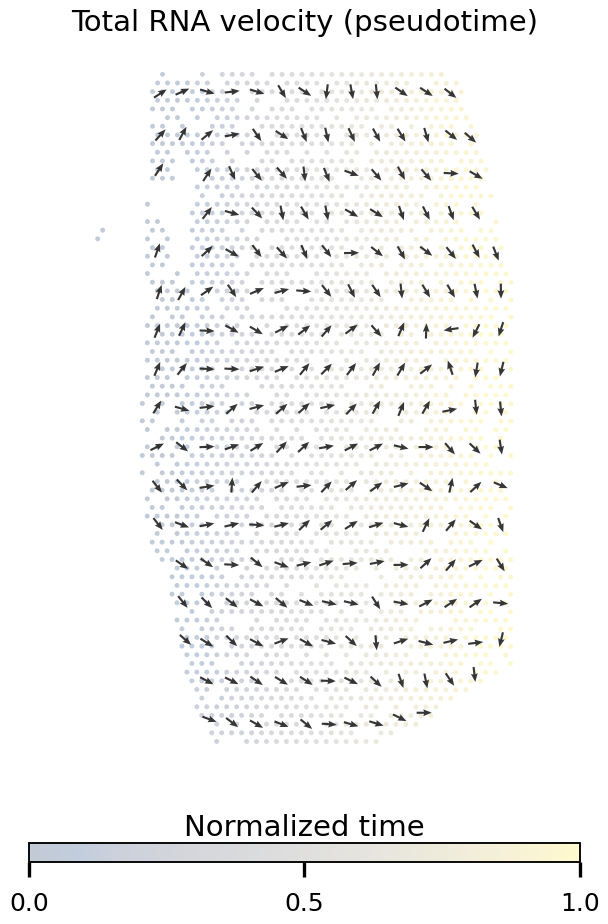

In [4]:
analysis = CellVOCALAnalysis.from_h5ad(cfg.eval.output_dir / "out.h5ad", config=cfg)
ccc = analysis.adata.uns["cv_ccc"]
n_spots = analysis.adata.n_obs
sample_overview = pd.DataFrame({"value": [
    str(analysis.adata.obs["condition"].iloc[0]),
    str(analysis.adata.obs["donor_id"].iloc[0]),
    f"{n_spots:,}",
    f"{analysis.adata.n_vars:,}",
    f'{analysis.adata.obs["cv_time"].min():.3f}–{analysis.adata.obs["cv_time"].max():.3f}',
    f'{len(ccc["event_influence"]):,}',
    f'{100 * np.unique(np.asarray(ccc["receiver"], dtype=int)).size / n_spots:.1f}%',
]}, index=["condition", "donor", "spots", "genes", "inferred-time range", "candidate CCC events", "receiver coverage"])
display(sample_overview)

with capture_output():
    velocity_plots = analysis.plot_velocity(output_dir=DATA_ROOT / "cellvocal" / SAMPLE / "velocity")
image_tiles = []
for path in velocity_plots:
    encoded = b64encode(Path(path).read_bytes()).decode("ascii")
    image_tiles.append(f'<img src="data:image/png;base64,{encoded}" alt="{Path(path).stem}" style="flex:1 1 0;min-width:0;width:49%;height:auto;object-fit:contain">')
display(HTML('<div style="display:flex;flex-wrap:nowrap;gap:8px;align-items:flex-start;width:100%">' + "".join(image_tiles) + "</div>"))

In [5]:
ccc = analysis.adata.uns["cv_ccc"]
module_index = np.asarray(ccc["module"], dtype=int)
valid = (module_index >= 0) & (module_index < len(ccc["lr_pairs"]))
lr_total_influence = (
    pd.DataFrame({"LR module": np.asarray(ccc["lr_pairs"], dtype=str)[module_index[valid]], "event_influence": np.asarray(ccc["event_influence"], dtype=float)[valid]})
    .query("event_influence > 0").groupby("LR module", as_index=False)["event_influence"].sum()
    .sort_values("event_influence", ascending=False)
)
lr_total_influence["share (%)"] = 100 * lr_total_influence["event_influence"] / lr_total_influence["event_influence"].sum()
display(lr_total_influence.round({"event_influence": 1, "share (%)": 1}))

,LR module,event_influence,share (%)
0,ANGPTL4->SDC1,457.3,25.6
2,CD99->CD99,348.6,19.5
3,CLDN1->CLDN1,315.5,17.7
6,LAMB2->ITGA1,237.1,13.3
1,ANGPTL4->SDC4,225.5,12.6
4,FN1->SDC1,146.0,8.2
5,FN1->SDC4,56.5,3.2


## Reuse communication analysis tools

The following examples use `pipeline.analysis.CellVOCALAnalysis`.
Calculations live in `utils/tools` and plots in `utils/viz`.
The three levels resolve a receiver's gene response, locate its
spatial sender catchment, and summarize source–section–state input
allocation. Capture spots are the observation units; input influence
and signed RNA velocity remain distinct.

In [6]:
from IPython import get_ipython
from matplotlib_inline.backend_inline import set_matplotlib_formats

get_ipython().run_line_magic("matplotlib", "inline")
set_matplotlib_formats("retina")
import matplotlib.pyplot as plt

## Compare communication event rates across conditions

The liver analysis uses all eight sections and seven biological donors. Positive
events targeting hepatocyte-enriched spots are counted by source class and LR
module; groups represented in every condition define the retained network.
Negative-binomial regression uses its section-wide event total as the offset and
clusters covariance by donor, so APAP 01 A/B remain technical sections of one
donor. The three planned contrasts share one BH correction family.

Only event and observation metadata are read for the other sections. This
comparison concerns relative event rates, not a causal effect or a velocity
contrast. The reusable methods live in `utils` and are exposed by
`CellVOCALAnalysis`.

,group_label,contrast,log2_rate_ratio,fdr,n_donors,inference_status
0,Hepatocyte | LAMB2->ITGA1,APAP vs Healthy,-0.967026,2.149191e-01,7,donor_clustered
1,Hepatocyte | LAMB2->ITGA1,APAP vs NonAE,-1.045593,1.822908e-01,7,donor_clustered
2,Hepatocyte | LAMB2->ITGA1,NonAE vs Healthy,0.078567,5.258905e-01,7,donor_clustered
3,Hepatocyte | CLDN1->CLDN1,APAP vs Healthy,0.514527,4.447935e-02,7,donor_clustered
4,Hepatocyte | CLDN1->CLDN1,APAP vs NonAE,0.735234,1.290631e-02,7,donor_clustered
5,Hepatocyte | CLDN1->CLDN1,NonAE vs Healthy,-0.220708,2.527800e-01,7,donor_clustered
6,Hepatocyte | ANGPTL4->SDC4,APAP vs Healthy,0.322523,5.405033e-04,7,donor_clustered
7,Hepatocyte | ANGPTL4->SDC4,APAP vs NonAE,0.583270,1.941442e-49,7,donor_clustered
8,Hepatocyte | ANGPTL4->SDC4,NonAE vs Healthy,-0.260748,1.290631e-02,7,donor_clustered
9,Hepatocyte | FN1->SDC4,APAP vs Healthy,-0.410418,2.972919e-01,7,donor_clustered


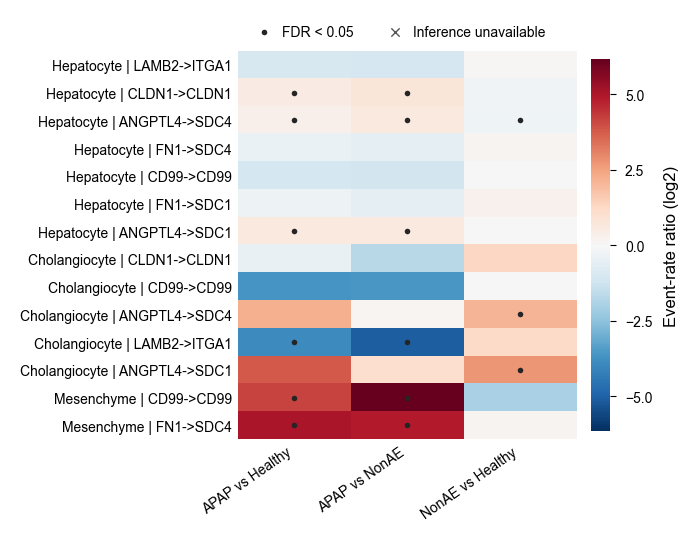

In [7]:
import h5py
from anndata.io import read_elem

SAMPLE_METADATA = pd.DataFrame([
    ("Healthy_liver_spatial_01", "Healthy", "Healthy_01"),
    ("Healthy_liver_spatial_02", "Healthy", "Healthy_02"),
    ("Healthy_liver_spatial_10", "Healthy", "Healthy_10"),
    ("APAP_liver_spatial_01_A", "APAP", "APAP_01"),
    ("APAP_liver_spatial_01_B", "APAP", "APAP_01"),
    ("APAP_liver_spatial_03", "APAP", "APAP_03"),
    ("NonAE_liver_spatial_03", "NonAE", "NonAE_03"),
    ("NonAE_liver_spatial_05", "NonAE", "NonAE_05"),
], columns=["sample", "condition", "donor"])
SOURCE_NAMES = {
    "Hepatocytes": "Hepatocyte", "MPs": "Macrophage", "Mesenchyme": "Mesenchyme",
    "Endothelia": "Endothelial", "Cholangiocytes": "Cholangiocyte",
    "T.cells": "T/NK", "ILCs": "T/NK", "B.cells": "B/Plasma",
    "Plasma": "B/Plasma", "Unidentified": "Unidentified",
}

def dominant_source(obs):
    columns = [name for name in obs if name.startswith("cellprop_")]
    values = np.nan_to_num(obs[columns].to_numpy(float), nan=-1.0)
    names = np.asarray([SOURCE_NAMES.get(c.removeprefix("cellprop_"), "Unidentified")
                        for c in columns])
    return pd.Series(names[values.argmax(axis=1)], index=obs.index)

event_tables = []
for sample in SAMPLE_METADATA["sample"]:
    path = DATA_ROOT / "cellvocal" / sample / "results" / "out.h5ad"
    with h5py.File(path, "r") as handle:
        obs = read_elem(handle["obs"])
        group = handle["uns/cv_ccc"]
        keys = ("sender", "receiver", "module", "lr_pairs", "event_influence",
                "module_activation_prob", "sender_share")
        events_only = ad.AnnData(obs=obs, uns={"cv_ccc": {
            key: read_elem(group[key]) for key in keys if key in group
        }})
    event = CellVOCALAnalysis(events_only, config=cfg).communication_events()
    keep = obs["cellprop_Hepatocytes"].to_numpy(float)[event.receiver] >= 0.5
    selected = event.loc[keep].copy()
    selected["sender_class"] = dominant_source(obs).to_numpy()[selected.sender]
    selected["sample"] = sample
    event_tables.append(selected[["sample", "sender_class", "module_name", "event_influence"]])

event_counts = analysis.prepare_communication_counts(
    pd.concat(event_tables, ignore_index=True), SAMPLE_METADATA,
    group_cols=("sender_class", "module_name"),
)
regression = analysis.communication_regression(
    event_counts, group_cols=("sender_class", "module_name"),
    reference="Healthy", alpha=1.0,
    contrasts={"APAP vs Healthy": ("APAP", "Healthy"),
               "APAP vs NonAE": ("APAP", "NonAE"),
               "NonAE vs Healthy": ("NonAE", "Healthy")},
)
display(regression[["group_label", "contrast", "log2_rate_ratio", "fdr",
                    "n_donors", "inference_status"]].head(12))
fig, ax = analysis.plot_communication_regression(regression)
display(fig)
plt.close(fig)

## Define receivers and the APAP matrix-associated readout

The receiver population, signature and focal input are specified before
examining response directions. Expression and all velocity components use
the same gene-specific input SD; the original signature denominator is
retained if a gene is unavailable. The coverage table makes this explicit.
These examples use SDs from the selected section and illustrate the reusable
tools, rather than reproducing cross-section publication scaling.

The six-gene signature is shared by the APAP fits; it is not compared as a
complete velocity programme across all clinical conditions. The all-donor
count regression above does not require common velocity-gene coverage.

In [8]:
a = analysis.adata
receiver_mask = a.obs["cellprop_Hepatocytes"].ge(0.5)
source_labels = dominant_source(a.obs)
FOCUS = 'ANGPTL4->SDC1'
PROGRAM_GENES = ['ANXA2', 'VIM', 'FN1', 'COL1A1', 'COL1A2', 'ACTA2']
MARKER_GENES = ['ANXA2', 'VIM', 'FN1']
scale_genes = [g for g in dict.fromkeys(PROGRAM_GENES + MARKER_GENES) if g in a.var_names]
columns = a.var_names.get_indexer(scale_genes)
x = a.layers["spliced"][receiver_mask.to_numpy()][:, columns]
x = x.toarray() if hasattr(x, "toarray") else np.asarray(x)
sd = x.std(axis=0)
floor = max(float(np.median(sd[sd > 0])) * 0.01, 1e-6) if np.any(sd > 0) else 1e-6
gene_scale = pd.Series(np.maximum(sd, floor), index=scale_genes)
scores = analysis.program_scores(PROGRAM_GENES, gene_scale=gene_scale, missing="omit")
incoming = analysis.incoming_influence()
display(pd.DataFrame({"gene": PROGRAM_GENES,
                      "available": [g in a.var_names for g in PROGRAM_GENES]}))

,gene,available
0,ANXA2,True
1,VIM,True
2,FN1,True
3,COL1A1,True
4,COL1A2,True
5,ACTA2,True


## Point level: resolve one receiver's gene response

Select the receiver with greatest focal input, without using its response
sign. The checkpoint supplies the fixed response basis and mixing gate;
no training is performed. Sender contributions must reconstruct each
module response, and their sum must agree with saved communication
velocity. The ledger retains all modules, grouping those not highlighted.
Total and intrinsic velocities remain separately available in the table.

,receiver,receiver_id,gene,gene_scale,ccc_velocity_reconstructed,ccc_velocity_saved,total_velocity,intrinsic_velocity
0,1607,APAP_liver_spatial_01_A:GCTGGCGGCGCATGCT-1,ANXA2,3.091020,-0.000112,-0.000112,-0.004638,-0.004527
1,1607,APAP_liver_spatial_01_A:GCTGGCGGCGCATGCT-1,VIM,4.623646,0.000721,0.000721,0.003110,0.002389
2,1607,APAP_liver_spatial_01_A:GCTGGCGGCGCATGCT-1,FN1,12.176351,0.000218,0.000218,0.001358,0.001141


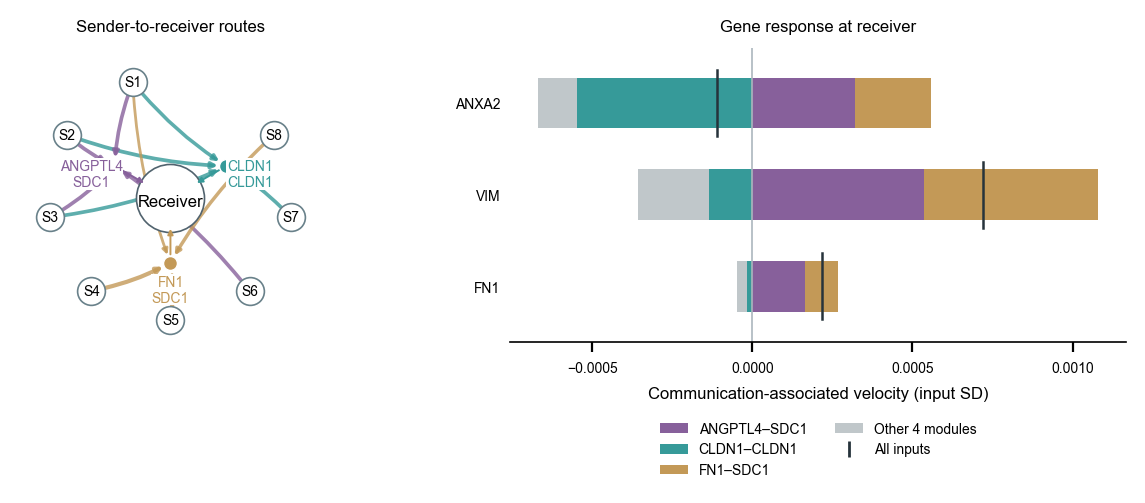

In [9]:
eligible = receiver_mask & incoming[FOCUS].gt(0)
if not eligible.any():
    raise ValueError("The selected section has no focal-input receivers.")
receiver_id = incoming.loc[eligible, FOCUS].idxmax()
receiver_index = int(a.obs_names.get_loc(receiver_id))
components = analysis.response_components()
marker_genes = [g for g in MARKER_GENES if g in a.var_names]
point = analysis.receiver_response(
    receiver_id, genes=marker_genes, gene_scale=gene_scale, components=components,
)
positive = incoming.loc[receiver_id].sort_values(ascending=False)
displayed_modules = [FOCUS] + [m for m in positive[positive > 0].index if m != FOCUS][:2]
fig, axes = analysis.plot_receiver_response(point, modules=displayed_modules)
display(point["gene_summary"], fig)
plt.close(fig)

## Tissue level: locate sender catchments and receiver dynamics

Routes remain in tissue coordinates. Receiver fill shows measured
signature expression and ring colour shows signed total velocity.
Width represents the magnitude of the attributed response across genes,
while source shares are computed from nonnegative influence.
All source classes and routes are retained in the tables. The inset is
centred on the same receiver as the point-level ledger; route selection
uses spatial position and input magnitude, never velocity sign.

,module_name,source_label,event_influence,n_events,n_senders,n_receivers,response_rms,programme_contribution,influence_fraction
0,ANGPTL4->SDC1,Hepatocyte,415.83708,1959,424,585,0.456313,0.144289,0.984582
1,ANGPTL4->SDC1,Macrophage,6.51169,29,5,22,0.007146,0.002260,0.015418


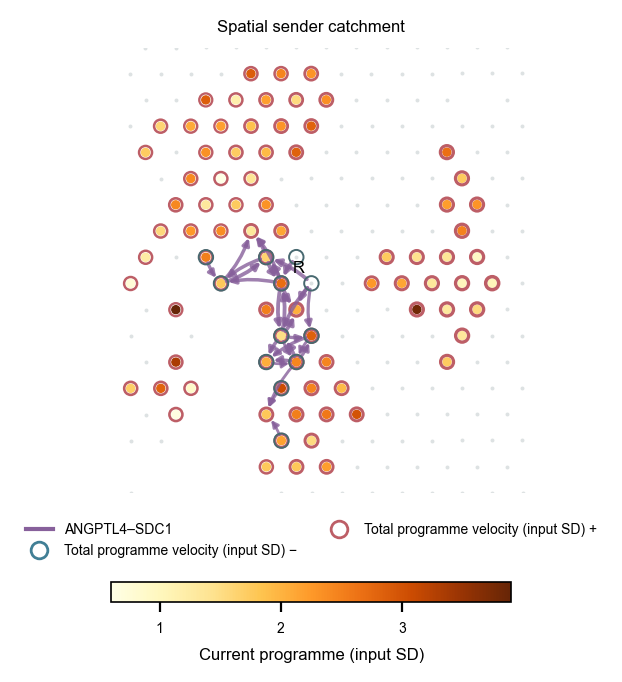

In [10]:
gene_weights = pd.Series(0.0, index=a.var_names)
available = scores.attrs["genes_available"]
gene_weights.loc[available] = 1 / (len(PROGRAM_GENES) * gene_scale.loc[available])
tissue = analysis.tissue_communication(
    modules=[FOCUS], receiver_mask=receiver_mask, source_labels=source_labels,
    observed_values=scores["current_expression"],
    velocity_values=scores["total_velocity"],
    observed_label="Current programme (input SD)",
    velocity_label="Total programme velocity (input SD)",
    gene_weights=gene_weights, **components,
)
xy = np.asarray(a.obsm["spatial"])[:, :2]
receiver_distance = np.linalg.norm(xy[receiver_mask.to_numpy()] - xy[receiver_index], axis=1)
# A comparable local view of about 80 receivers, chosen using position only.
radius = float(np.sort(receiver_distance)[min(80, len(receiver_distance) - 1)])
fig, ax = analysis.plot_sender_catchment(
    tissue, focus_receiver=receiver_index, radius=radius,
    max_receivers=10, max_routes_per_receiver=3,
)
display(tissue["source_summary"], fig)
plt.close(fig)

## Summary level: source → section → observed receiver state

ANGPTL4–SDC1 input is summarized across the three APAP sections in a
source-to-section-to-ANXA2-state Sankey diagram. Width is the sum of
conditional sender share multiplied by module activation probability, divided by
the number of hepatocyte-enriched receivers and weighted equally by
donor. APAP 01 A/B each receive one quarter of the total donor weight;
APAP 03 receives one half. Zero-input receivers remain in the denominator.

Low, intermediate and high states use donor-balanced tertiles of measured
ANXA2 log expression. Both sides of the diagram are marginals of the same
conserved input table. These flows describe input allocation, not signed
total velocity or cell-state transitions.

,section,n_receivers,section_weight,weighted_influence
0,APAP_liver_spatial_01_A,1836,0.25,0.057509
1,APAP_liver_spatial_01_B,1856,0.25,0.075030
2,APAP_liver_spatial_03,643,0.50,0.123051


,quantile,value,method
0,0.333333,1.719731,weighted quantiles across all eligible receivers
1,0.666667,2.025135,weighted quantiles across all eligible receivers


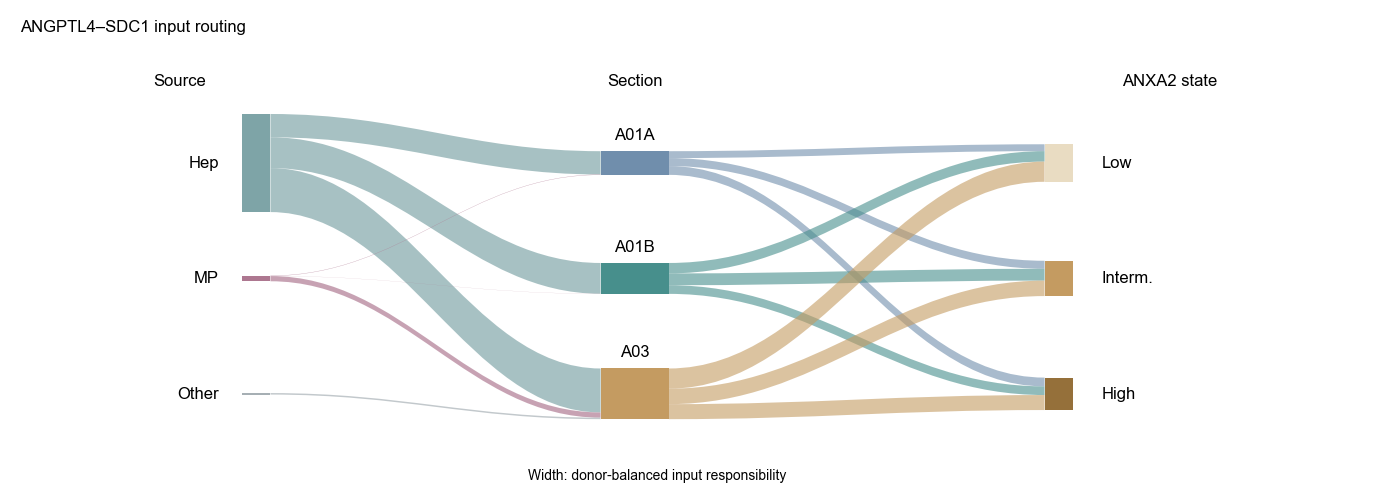

In [11]:
ROUTING_SAMPLES = ["APAP_liver_spatial_01_A", "APAP_liver_spatial_01_B", "APAP_liver_spatial_03"]

import h5py
from anndata.io import read_elem

routing_sections = {}
for section in ROUTING_SAMPLES:
    path = DATA_ROOT / "cellvocal" / section / "results" / "out.h5ad"
    with h5py.File(path, "r") as handle:
        obs = read_elem(handle["obs"])
        group = handle["uns/cv_ccc"]
        keys = ("sender", "receiver", "module", "lr_pairs", "event_influence",
                "module_activation_prob", "sender_share")
        routing_sections[section] = ad.AnnData(obs=obs, uns={"cv_ccc": {
            key: read_elem(group[key]) for key in keys if key in group
        }})

routing_masks = {s: value.obs["cellprop_Hepatocytes"].ge(.5).to_numpy()
                 for s, value in routing_sections.items()}
routing_sources = {s: dominant_source(value.obs) for s, value in routing_sections.items()}
routing_donors = dict(SAMPLE_METADATA.set_index("sample").loc[ROUTING_SAMPLES, "donor"])
statistics = analysis.communication_statistics(
    FOCUS, sections=routing_sections, receiver_masks=routing_masks,
    source_labels=routing_sources, state_values="anxa2_log_expression",
    donors=routing_donors, weighting="donor",
    source_groups={"Hepatocyte": "Hepatocyte", "Macrophage": "Macrophage"},
    source_order=["Hepatocyte", "Macrophage", "Other"],
)
fig, ax = analysis.plot_communication_statistics(
    statistics, state_title="ANXA2 state", title="ANGPTL4–SDC1 input routing",
    source_labels={"Hepatocyte": "Hep", "Macrophage": "MP"},
    section_labels=dict(zip(ROUTING_SAMPLES, ["A01A", "A01B", "A03"])),
    state_labels={"Intermediate": "Interm."},
)

display(statistics["sections"][["section", "n_receivers", "section_weight", "weighted_influence"]],
        statistics["thresholds"], fig)
plt.close(fig)
# Direct plotting data: one row per source, section, state and selected module.
# statistics["flow"].to_csv("input_routing.csv", index=False)
